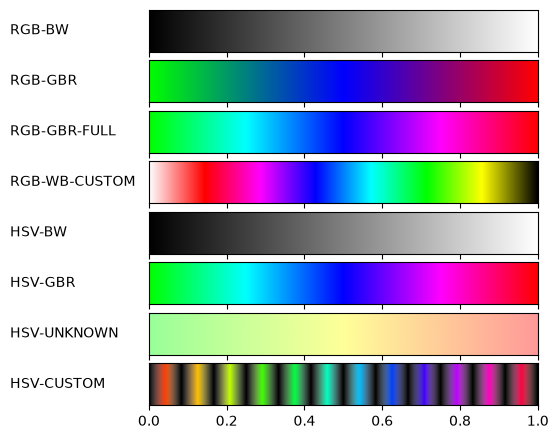

In [1]:

import matplotlib
#matplotlib.use('Agg')                       # So that we can render files without GUI
import matplotlib.pyplot as plt
from matplotlib import rc
import numpy as np

from matplotlib import colors

def plot_color_gradients(gradients, names):
    # For pretty latex fonts (commented out, because it does not work on some machines)
    #rc('text', usetex=True) 
    #rc('font', family='serif', serif=['Times'], size=10)
    rc('legend', fontsize=10)

    column_width_pt = 400         # Show in latex using \the\linewidth
    pt_per_inch = 72
    size = column_width_pt / pt_per_inch

    fig, axes = plt.subplots(nrows=len(gradients), sharex=True, figsize=(size, 0.75 * size))
    fig.subplots_adjust(top=1.00, bottom=0.05, left=0.25, right=0.95)


    for ax, gradient, name in zip(axes, gradients, names):
        # Create image with two lines and draw gradient on it
        img = np.zeros((2, 1024, 3))
        for i, v in enumerate(np.linspace(0, 1, 1024)):
            img[:, i] = gradient(v)

        im = ax.imshow(img, aspect='auto')
        im.set_extent([0, 1, 0, 1])
        ax.yaxis.set_visible(False)

        pos = list(ax.get_position().bounds)
        x_text = pos[0] - 0.25
        y_text = pos[1] + pos[3]/2.
        fig.text(x_text, y_text, name, va='center', ha='left', fontsize=10)

    plt.show()

def linear_interpolation(x1, x2, v):
    return x1 + v * (x2 - x1)

def linear_interpolation_color(colour_1, colour_2, v):
    r = linear_interpolation(colour_1[0], colour_2[0], v)
    g = linear_interpolation(colour_1[1], colour_2[1], v)
    b = linear_interpolation(colour_1[2], colour_2[2], v)
    return(r,g,b)

def gradient(colours: list[tuple[float,float,float]], v):
 
    num_of_transition = len(colours)-1
    index = min(int(np.floor(v*num_of_transition)), num_of_transition -1)
    t = v * num_of_transition - index

    colour_1 = colours[index]
    colour_2 = colours[index+1]

    return linear_interpolation_color(colour_1, colour_2, t)

def hsv2rgb(h: float, s: float, v: float):
    if s == 0.0:
        return (v, v, v)

    if h >= 360:
        h %= 360
    
    base_color = int(np.floor(h/60))
    color_fraction = h/60 - base_color

    p = v * (1.0 - s)
    t = v * (1.0 - (s * (1.0 - color_fraction)))
    q = v * (1.0 - s * color_fraction)

    if base_color == 0:     #(1,0,0) => (1,1,0)
        return(v,t,p)
    elif base_color == 1:   #(1,1,0) => (0,1,0)
        return(q,v,p)
    elif base_color == 2:   #(0,1,0) => (0,1,1)
        return(p,v,t)
    elif base_color == 3:   #(0,1,1) => (0,0,1)
        return(p,q,v)
    elif base_color == 4:   #(0,0,1) => (1,0,1)
        return (t,p,v)
    else:                   #(1,0,1) => (1,0,0)
        return (v,p,q)

def gradient_rgb_bw(v: float):
    return (v, v, v)


def gradient_rgb_gbr(v: float):
    colours = [
        (0,1,0),  # Green
        (0,0,1),  # Blue
        (1,0,0)   # Red
    ]
    return gradient(colours, v)


def gradient_rgb_gbr_full(v: float):
    colours = [
        (0, 1, 0),  # Green
        (0, 1, 1),  # Cyan
        (0, 0, 1),  # Blue
        (1, 0, 1),  # Magenta
        (1, 0, 0),  # Red
    ]  
    return gradient(colours, v)

    

def gradient_rgb_wb_custom(v: float):
    colours = [
    (1.0, 1.0, 1.0), # White
    (1.0, 0.0, 0.0), # Red
    (1.0, 0.0, 1.0), # Magenta
    (0.0, 0.0, 1.0), # Blue
    (0.0, 1.0, 1.0), # Cyan
    (0.0, 1.0, 0.0), # Green
    (1.0, 1.0, 0.0), # Yellow
    (0.0, 0.0, 0.0)  # Black
]
    return gradient(colours, v)


def gradient_hsv_bw(v: float):
    #saturation set to 0 -> range black to white
    return hsv2rgb(90, 0, v)


def gradient_hsv_gbr(v: float):
    hsv_colours = [
        (120,1,1), # Green
        (240,1,1), # Blue
        (360,1,1), # Red
    ]
    h, s, val = gradient(hsv_colours, v)
    return hsv2rgb(h,s,val)

def gradient_hsv_unknown(v: float):
    hsv_colours = [
        (120,0.4,1), # Green
        (0,0.4,1), # Red
    ]
    h,s,val = gradient(hsv_colours, v)
    #saturation set to 0.4
    return hsv2rgb(h, s, val)


#this gradient should look like box of crayons
def gradient_hsv_custom(v: float):
    number_of_segments = 24
    index = int(np.floor(number_of_segments * v))
    s = v*number_of_segments - index
    if index % 2 == 0:
        return hsv2rgb(v*360, s, s)
    else:
        return hsv2rgb(v*360, 1-s, 1-s)

    

if __name__ == '__main__':
    def toname(g):
        return g.__name__.replace('gradient_', '').replace('_', '-').upper()

    gradients = (gradient_rgb_bw, gradient_rgb_gbr, gradient_rgb_gbr_full, gradient_rgb_wb_custom,
                 gradient_hsv_bw, gradient_hsv_gbr, gradient_hsv_unknown, gradient_hsv_custom)

    plot_color_gradients(gradients, [toname(g) for g in gradients])


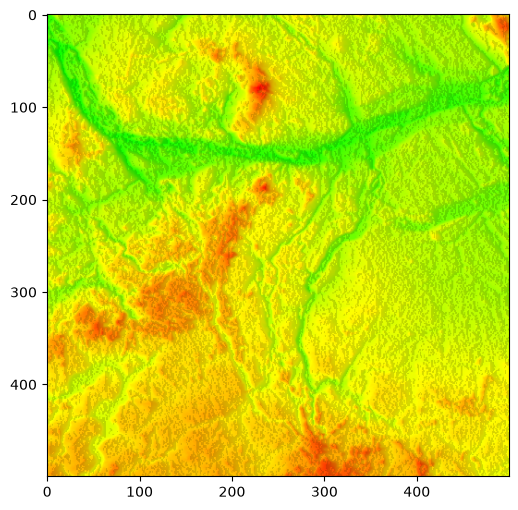

In [7]:

import numpy as np
import matplotlib.pyplot as plt

def paint_map(matrix, h, w):
    colors = [
        (120,1,1),
        (60,1,1),
        (0,1,1)
    ]
    value = matrix[h, w]
    hue,s,v = gradient(colors,value)
    
    if w > 0:
        left = matrix[h, w-1]
        if left > value:
            v -= 0.15
        elif left < value:
            v += 0.15

    v = max(0.0, min(1.0, v))
    return hsv2rgb(hue, s, v)
        


def hsv2rgb(h: float, s: float, v: float):
    if s == 0.0:
        return (v, v, v)

    if h >= 360:
        h %= 360
    
    base_color = int(np.floor(h/60))
    color_fraction = h/60 - base_color

    p = v * (1.0 - s)
    t = v * (1.0 - (s * (1.0 - color_fraction)))
    q = v * (1.0 - s * color_fraction)

    if base_color == 0:     #(1,0,0) => (1,1,0)
        return(v,t,p)
    elif base_color == 1:   #(1,1,0) => (0,1,0)
        return(q,v,p)
    elif base_color == 2:   #(0,1,0) => (0,1,1)
        return(p,v,t)
    elif base_color == 3:   #(0,1,1) => (0,0,1)
        return(p,q,v)
    elif base_color == 4:   #(0,0,1) => (1,0,1)
        return (t,p,v)
    else:                   #(1,0,1) => (1,0,0)
        return (v,p,q)



def linear_interpolation(x1, x2, v):
    return x1 + v * (x2 - x1)


def linear_interpolation_color(colour_1, colour_2, v):
    r = linear_interpolation(colour_1[0], colour_2[0], v)
    g = linear_interpolation(colour_1[1], colour_2[1], v)
    b = linear_interpolation(colour_1[2], colour_2[2], v)
    return(r,g,b)


def gradient(colours: list[tuple[float,float,float]], v):
 
    num_of_transition = len(colours)-1
    index = min(int(np.floor(v*num_of_transition)), num_of_transition -1)
    t = v * num_of_transition - index

    colour_1 = colours[index]
    colour_2 = colours[index+1]

    return linear_interpolation_color(colour_1, colour_2, t)


with open('pliki/big.dem.txt') as file:
    width, height, points = [int(value) for value in file.readline().split(' ')]
    matrix = np.loadtxt(file)

max_value = np.max(matrix)
min_value = np.min(matrix)

normalized_matrix = (matrix - min_value)/(max_value - min_value) 
img = np.zeros((height, width, 3))

for h in range(height):
    for w in range(width):
        img[h, w] = paint_map(normalized_matrix, h, w)
        

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img)
    
plt.savefig('map.pdf', bbox_inches='tight')
plt.show()
    

### Basic Shading (Neighbor Comparison)

This method is simple: it iterates through the normalized matrix, compares each cell's elevation with its neighbor, and adjusts the brightness of the current cell. However, this approach leaves the map with visible artifacts.

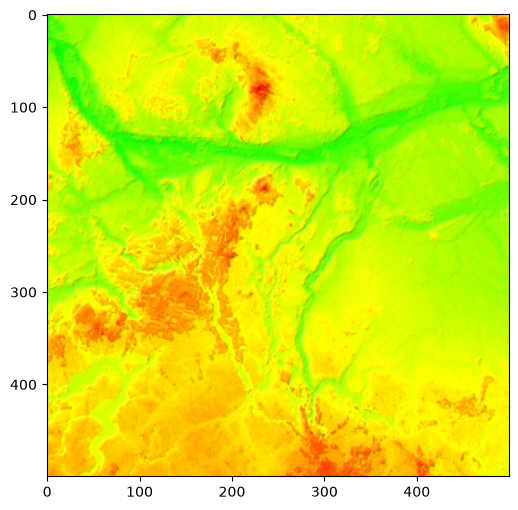

In [10]:

import numpy as np
import matplotlib.pyplot as plt

def paint_map_adv(raw_matrix, norm_matrix, x, y, distance, sun_vec):
    colors = [
        (120,1,1),
        (60,1,1),
        (0,1,1)
    ]
    value = norm_matrix[y, x]
    hue, s, v = gradient(colors, value)
    
    if x < raw_matrix.shape[1] - 1 and y < raw_matrix.shape[0] - 1:
        #checking difference between neighbours
        dz_dx = raw_matrix[y, x+1] - raw_matrix[y, x]
        dz_dy = raw_matrix[y+1, x] - raw_matrix[y, x] 

        #creating reflecting vector
        vector = np.array([-dz_dx, -dz_dy, distance])
        vector = vector / np.linalg.norm(vector)

        cos_alpha = np.dot(sun_vec, vector)
        diff = cos_alpha - sun_vec[2]
        
        intensity = 2  
        if diff > 0:
            s = max(0.0, min(1.0, s - diff * intensity))
        else:
            v = max(0.0, min(1.0, v + diff * intensity))

    return hsv2rgb(hue, s, v)
        


def hsv2rgb(h: float, s: float, v: float):
    if s == 0.0:
        return (v, v, v)

    if h >= 360:
        h %= 360
    
    base_color = int(np.floor(h/60))
    color_fraction = h/60 - base_color

    p = v * (1.0 - s)
    t = v * (1.0 - (s * (1.0 - color_fraction)))
    q = v * (1.0 - s * color_fraction)

    if base_color == 0:     #(1,0,0) => (1,1,0)
        return(v,t,p)
    elif base_color == 1:   #(1,1,0) => (0,1,0)
        return(q,v,p)
    elif base_color == 2:   #(0,1,0) => (0,1,1)
        return(p,v,t)
    elif base_color == 3:   #(0,1,1) => (0,0,1)
        return(p,q,v)
    elif base_color == 4:   #(0,0,1) => (1,0,1)
        return (t,p,v)
    else:                   #(1,0,1) => (1,0,0)
        return (v,p,q)



def linear_interpolation(x1, x2, v):
    return x1 + v * (x2 - x1)


def linear_interpolation_color(colour_1, colour_2, v):
    r = linear_interpolation(colour_1[0], colour_2[0], v)
    g = linear_interpolation(colour_1[1], colour_2[1], v)
    b = linear_interpolation(colour_1[2], colour_2[2], v)
    return(r,g,b)


def gradient(colours: list[tuple[float,float,float]], v):
 
    num_of_transition = len(colours)-1
    index = min(int(np.floor(v*num_of_transition)), num_of_transition -1)
    t = v * num_of_transition - index

    colour_1 = colours[index]
    colour_2 = colours[index+1]

    return linear_interpolation_color(colour_1, colour_2, t)


with open('pliki/big.dem.txt') as file:
    width, height, distance = [int(value) for value in file.readline().split(' ')]
    distance /= 100
    matrix = np.loadtxt(file)

max_value = np.max(matrix)
min_value = np.min(matrix)

normalized_matrix = (matrix - min_value)/(max_value - min_value) 
img = np.zeros((height, width, 3))
sun = np.array([-1,-1,1])
sun = sun / np.linalg.norm(sun)

for h in range(height):
    for w in range(width):
        img[h, w] = paint_map_adv(matrix, normalized_matrix, w, h, distance, sun)
        

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img)
    
plt.savefig('map.pdf', bbox_inches='tight')
plt.show()
    
    


### Advanced Shading (Sun Vector Illumination)

This approach uses a sun ray vector to compute shading, which creates a much smoother finish without pixelated artifacts.